# 02 — Exploratory data analysis

**Objective.** Understand numeric and categorical distributions, missingness structure,
correlations and feature/outcome relationships. **Method.** Univariate and bivariate charts
on the raw training data (the single invalid label has negligible visual impact and is removed
in notebook 03). All figures are saved to `models/figures/` for reuse in the Streamlit EDA page.

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
for p in (ROOT, ROOT / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.cirrhosis import config, paths, data, features, preprocessing, models, evaluation, inference

paths.ensure_dirs()
for sub in ("data_quality", "cleaning", "experiments", "final_evaluation"):
    (paths.REPORTS_DIR / sub).mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="Blues_d")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "figure.autolayout": True})
SEED = config.RANDOM_SEED
print("Environment ready; seed =", SEED)

Environment ready; seed = 42


In [2]:
train, test, submission = data.load_raw()
numeric = config.RAW_NUMERIC
categorical = config.RAW_CATEGORICAL

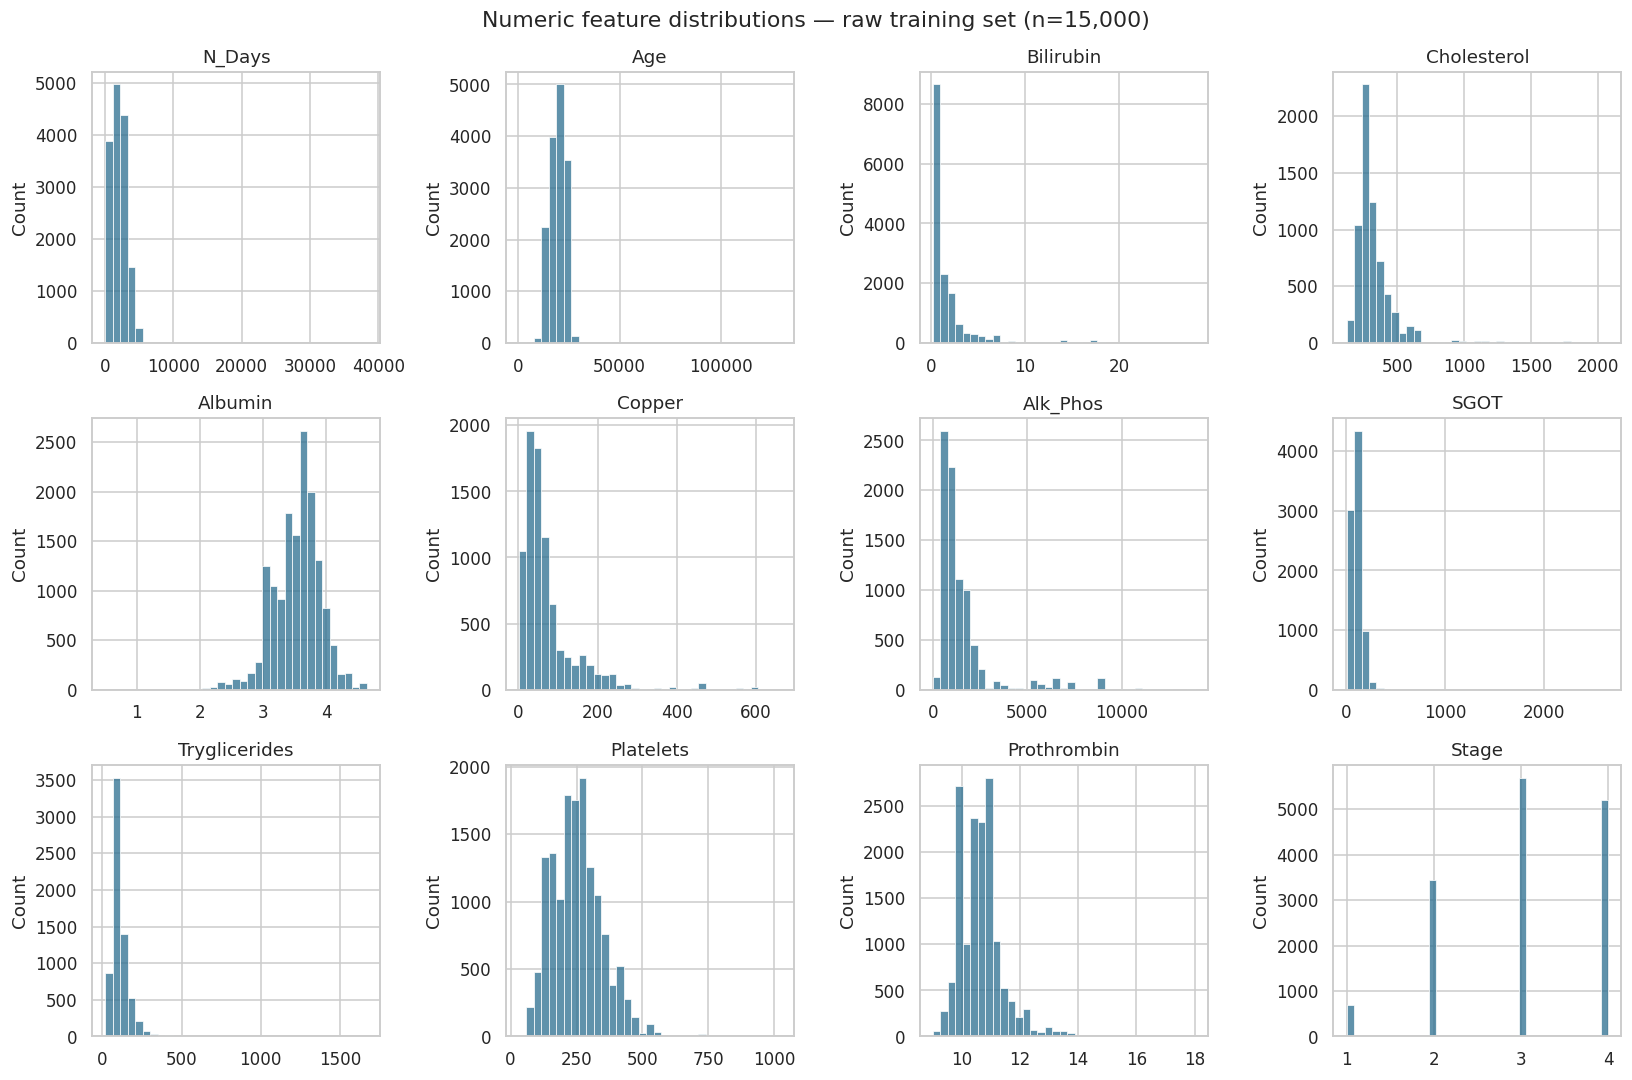

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, col in zip(axes.ravel(), numeric):
    sns.histplot(train[col].dropna(), ax=ax, kde=False, bins=35, color="#2B6E8F")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Numeric feature distributions — raw training set (n=15,000)")
fig.savefig(paths.FIGURES_DIR / "02_numeric_distributions.png", bbox_inches="tight")
plt.show()

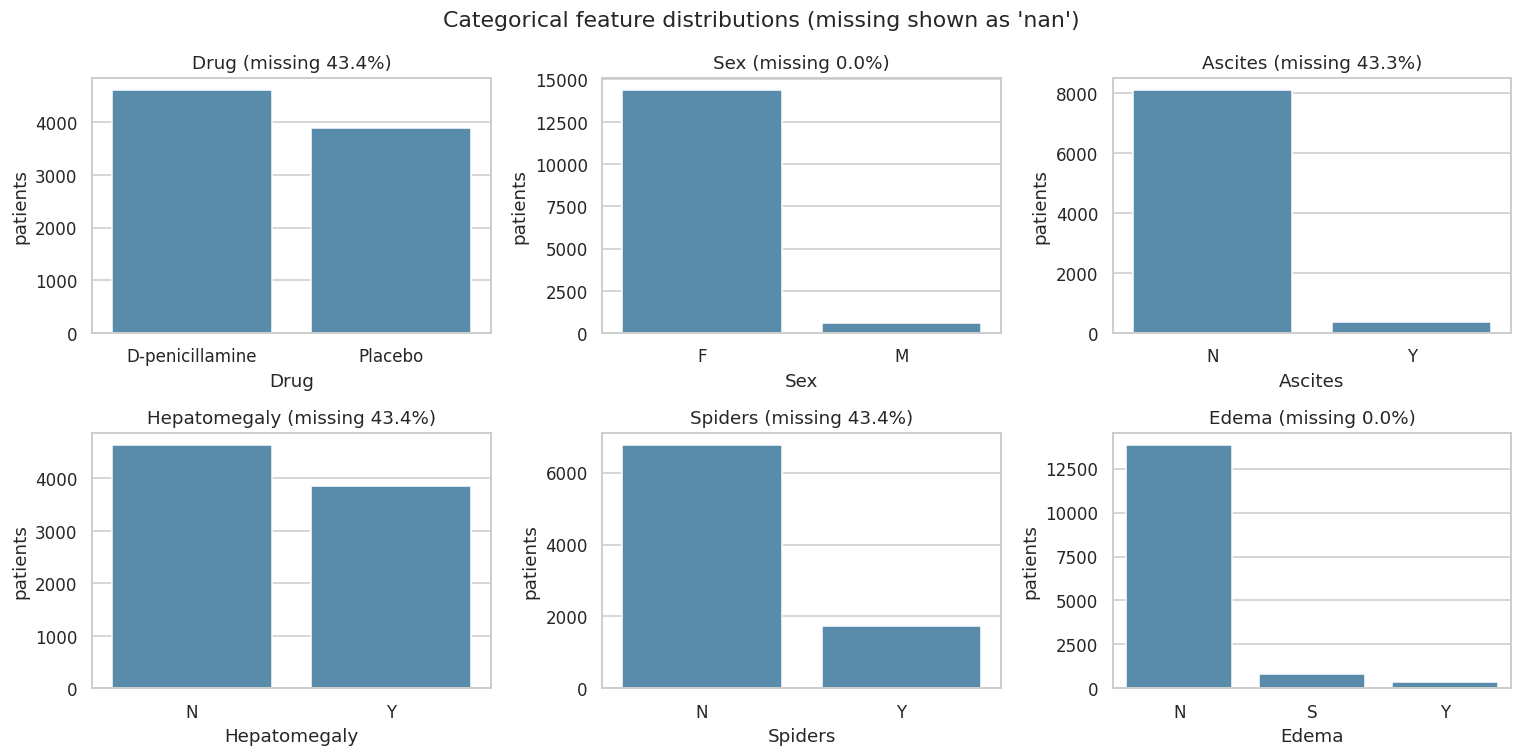

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), categorical):
    order = train[col].value_counts(dropna=False).index.astype(str)
    counts = train[col].astype(str).value_counts().reindex(order)
    sns.barplot(x=order, y=counts.values, ax=ax, color="#4A90B8")
    ax.set_title(f"{col} (missing {train[col].isna().mean():.1%})")
    ax.set_ylabel("patients")
fig.suptitle("Categorical feature distributions (missing shown as 'nan')")
fig.savefig(paths.FIGURES_DIR / "02_categorical_distributions.png", bbox_inches="tight")
plt.show()

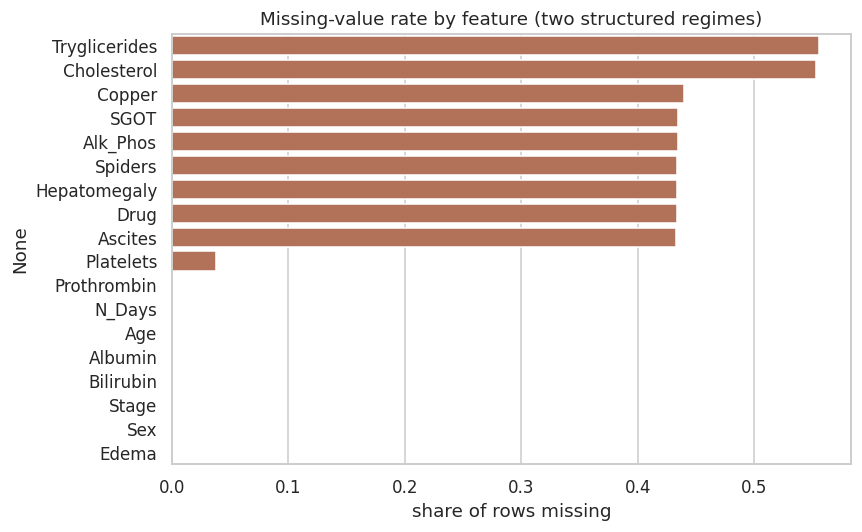

Tryglicerides    55.6
Cholesterol      55.3
Copper           44.0
SGOT             43.4
Alk_Phos         43.4
Spiders          43.4
Hepatomegaly     43.4
Drug             43.4
Ascites          43.3
Platelets         3.8
Prothrombin       0.1
N_Days            0.0
Age               0.0
Albumin           0.0
Bilirubin         0.0
Stage             0.0
Sex               0.0
Edema             0.0


In [5]:
missing = train[config.RAW_FEATURES].isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#C06C4A")
ax.set_title("Missing-value rate by feature (two structured regimes)")
ax.set_xlabel("share of rows missing")
fig.savefig(paths.FIGURES_DIR / "02_missingness.png", bbox_inches="tight")
plt.show()
print((missing * 100).round(1).to_string())

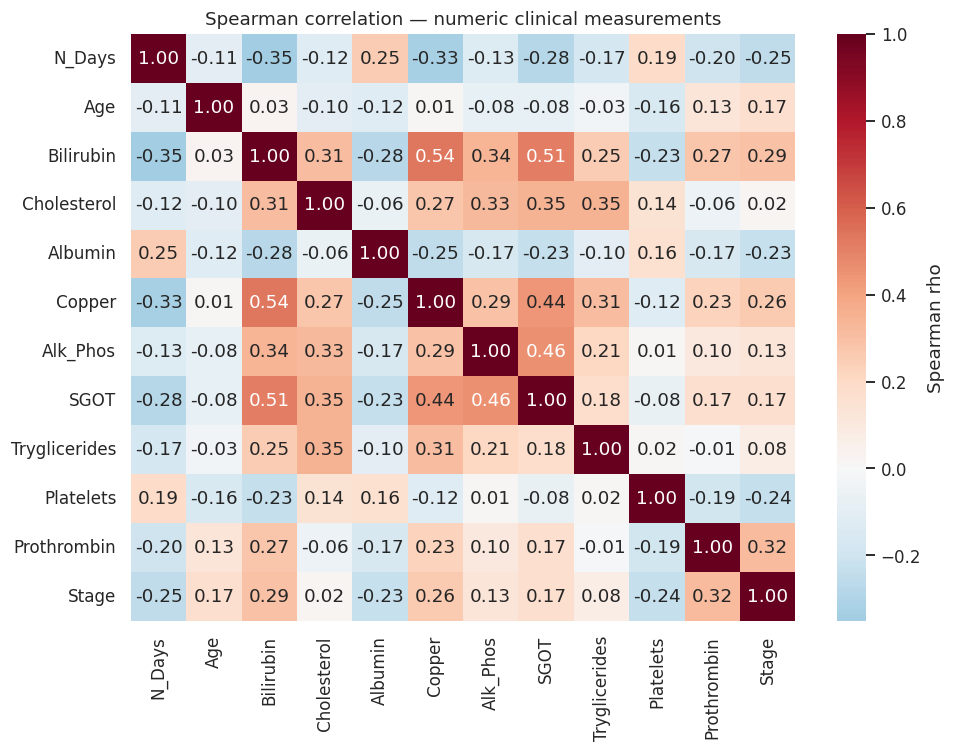

In [6]:
corr = train[numeric].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "Spearman rho"})
ax.set_title("Spearman correlation — numeric clinical measurements")
fig.savefig(paths.FIGURES_DIR / "02_correlation.png", bbox_inches="tight")
plt.show()

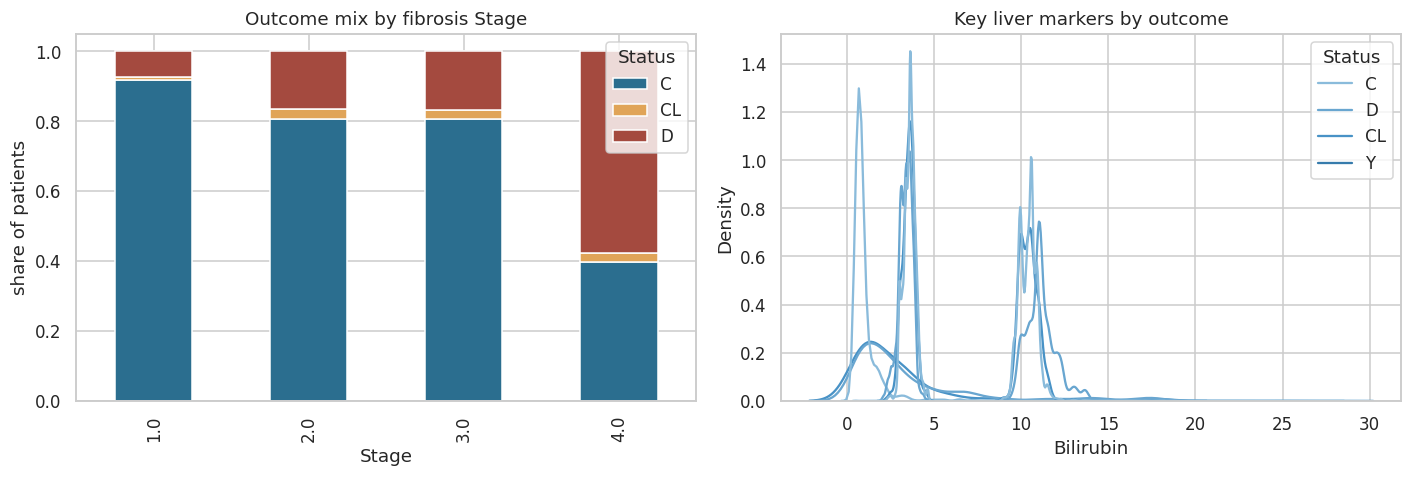

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ct = pd.crosstab(train["Stage"], train[config.TARGET], normalize="index")
ct.reindex(columns=config.CLASS_LABELS).plot(kind="bar", stacked=True, ax=axes[0],
    color=["#2B6E8F", "#E0A458", "#A44A3F"])
axes[0].set_title("Outcome mix by fibrosis Stage")
axes[0].set_ylabel("share of patients")
for col in ["Bilirubin", "Albumin", "Prothrombin"]:
    sns.kdeplot(data=train, x=col, hue=config.TARGET, common_norm=False, ax=axes[1])
axes[1].set_title("Key liver markers by outcome")
fig.savefig(paths.FIGURES_DIR / "02_target_relationships.png", bbox_inches="tight")
plt.show()

## Interpretation & decisions

- Bilirubin, Albumin and Prothrombin show clear separation between outcomes — clinically
  plausible severity signals that justify the Bilirubin/Albumin ratio feature.
- Missingness concentrates on the same 9 columns for ~43% of rows: a synthetic "regime" effect.
  Median imputation plus an explicit missing-count feature retains this information without
  inventing values from test data.
- Strong monotone correlations among liver enzymes are expected; scaling keeps linear models
  stable while tree ensembles are unaffected by monotone transforms.